# Fuzzy c-means clustering with training data

In this notebook, the fuzzy c-means algorithm is tested using signals generated with the Gilmore-akulichev model using the a range of frequencies and intensities. This is carried out to ensure that a single trained algorithm can be used to predict the stability of a range of cavitation signals measured under consistent conditions.

In [108]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [109]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Set pararmeters for bubble dynamics model

In [110]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
real_sampling_rate = 25E6
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db20"
levels = 4
mode = "symmetric"

step = int(sampling_rate/real_sampling_rate)

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [111]:
def generate_training_data_with_wavelet(wavelet):
    wpt_df = None
    for frequency in [i * 1E5 for i in range(8, 10)]:
        for pac in [-i * 1E4 for i in range(1, 20)]:
            data = train.generate_data(R_init, Rdot_init, frequency, pac, t_plot, tstep, r_measure)
            if max(data) > 70 or np.isnan(data).any():  # filter out failed dynamics model computations
                continue
            data = (data - np.mean(data)) / np.std(data)
            data += np.random.normal(0, std_noise, size=len(data))

            # Generate traning data using the wavelet transform
            training_data = train.generate_training_data(
                data[::step], levels, wavelet, mode, 
                min_energy=0,
                include_low_energy=0.1, 
                print_nodes_kept=False
            )

            if wpt_df is None:  # Init dataframe
                wpt_df = training_data
            else:  # Add data to dataframe
                wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

    # Add noise samples
    add_noise = .1  # 1/10 of the dataset is noise
    n = wpt_df.shape[0]
    n_noise_samples = int(n * add_noise / (1 - add_noise))
    for _ in range(n_noise_samples):
        noise = np.random.normal(0, std_noise, size=len(data))
        training_data = train.generate_training_data(noise[::step], levels, wavelet, mode)
        wpt_df= pd.concat([wpt_df, training_data], ignore_index=True)
    return wpt_df

In [112]:
wpt_df = generate_training_data_with_wavelet(wavelet)

### Training

Train fuzzy c-means on the generated data

In [113]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

#Parameters for Fuzzy C-means
no_clusters = 4
m = 2
error = 1e-6
classifying_metrics = ["log energy", "level entropy", "kurtosis"]

def train_c_means(wpt_df):
    # Get data
    data_train = wpt_df[classifying_metrics]

    # Standardise data
    scaler = StandardScaler()
    data_train_normalised = scaler.fit_transform(data_train)

    # Fuzzy C-Means clustering
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        data_train_normalised.T,
        c=no_clusters,
        m=m,
        error=error,
        maxiter=100,
    )
    # print("number of iterations:", p)
    # Cluster centres
    centers = scaler.inverse_transform(cntr)
    # print("centers:", centers)
    # Membership matrix
    membership_matrix = u.T

    # Hard cluster assignments
    labels = np.argmax(membership_matrix, axis=1)
    # for i in range(no_clusters):
    #     print(f"label {i} count:", list(labels).count(i))

    # membership_results = pd.DataFrame()
    # for i, membership in enumerate(membership_matrix):
    #     membership_results.loc[i, "hard assignment"] = labels[i]
    #     for j in range(no_clusters):
    #         membership_results.loc[i, f"membership {j}"] = membership[j]

    # membership_results.head()
    return data_train, labels, data_train_normalised, centers, cntr, scaler

data_train, labels, data_train_normalised, centers, cntr, scaler = train_c_means(wpt_df)

### Numerical studies

In [114]:
wavelets = [f"db{i}" for i in range(4, 21)]

In [115]:
from sklearn.metrics import silhouette_score
scores = []
for wavelet in wavelets:
    print(wavelet)
    wpt_df = generate_training_data_with_wavelet(wavelet)
    _, _labels, _data_train_normalised, *_   = train_c_means(wpt_df)
    scores.append(silhouette_score(_data_train_normalised, _labels)) 

db4
db5
db6
db7
db8


c:\Users\maxau\OneDrive\Codes\WPT-Cavitation\notebooks\..\wavelet_transform\utils\bubbledynamics.py:178: RuntimeWarning: invalid value encountered in sqrt
  nsound_speed_instantaneous = np.sqrt(


db9


c:\Users\maxau\OneDrive\Codes\WPT-Cavitation\notebooks\..\wavelet_transform\utils\bubbledynamics.py:178: RuntimeWarning: invalid value encountered in sqrt
  nsound_speed_instantaneous = np.sqrt(


db10
db11
db12
db13
db14


c:\Users\maxau\OneDrive\Codes\WPT-Cavitation\notebooks\..\wavelet_transform\utils\bubbledynamics.py:178: RuntimeWarning: invalid value encountered in sqrt
  nsound_speed_instantaneous = np.sqrt(


db15


c:\Users\maxau\OneDrive\Codes\WPT-Cavitation\notebooks\..\wavelet_transform\utils\bubbledynamics.py:178: RuntimeWarning: invalid value encountered in sqrt
  nsound_speed_instantaneous = np.sqrt(


db16
db17
db18
db19
db20


c:\Users\maxau\OneDrive\Codes\WPT-Cavitation\notebooks\..\wavelet_transform\utils\bubbledynamics.py:178: RuntimeWarning: invalid value encountered in sqrt
  nsound_speed_instantaneous = np.sqrt(


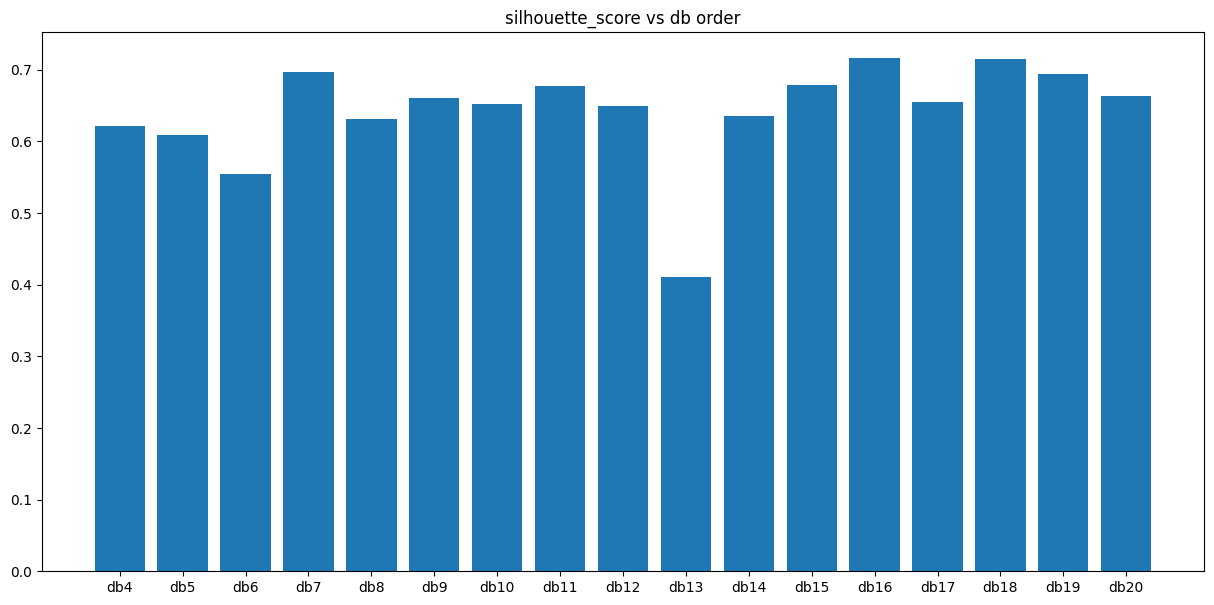

In [116]:
fig, ax = plt.subplots()
fig.set_size_inches(15, 7)
plt.bar(wavelets, scores)
plt.title("silhouette_score vs db order")
plt.show()

Plotting clustering results

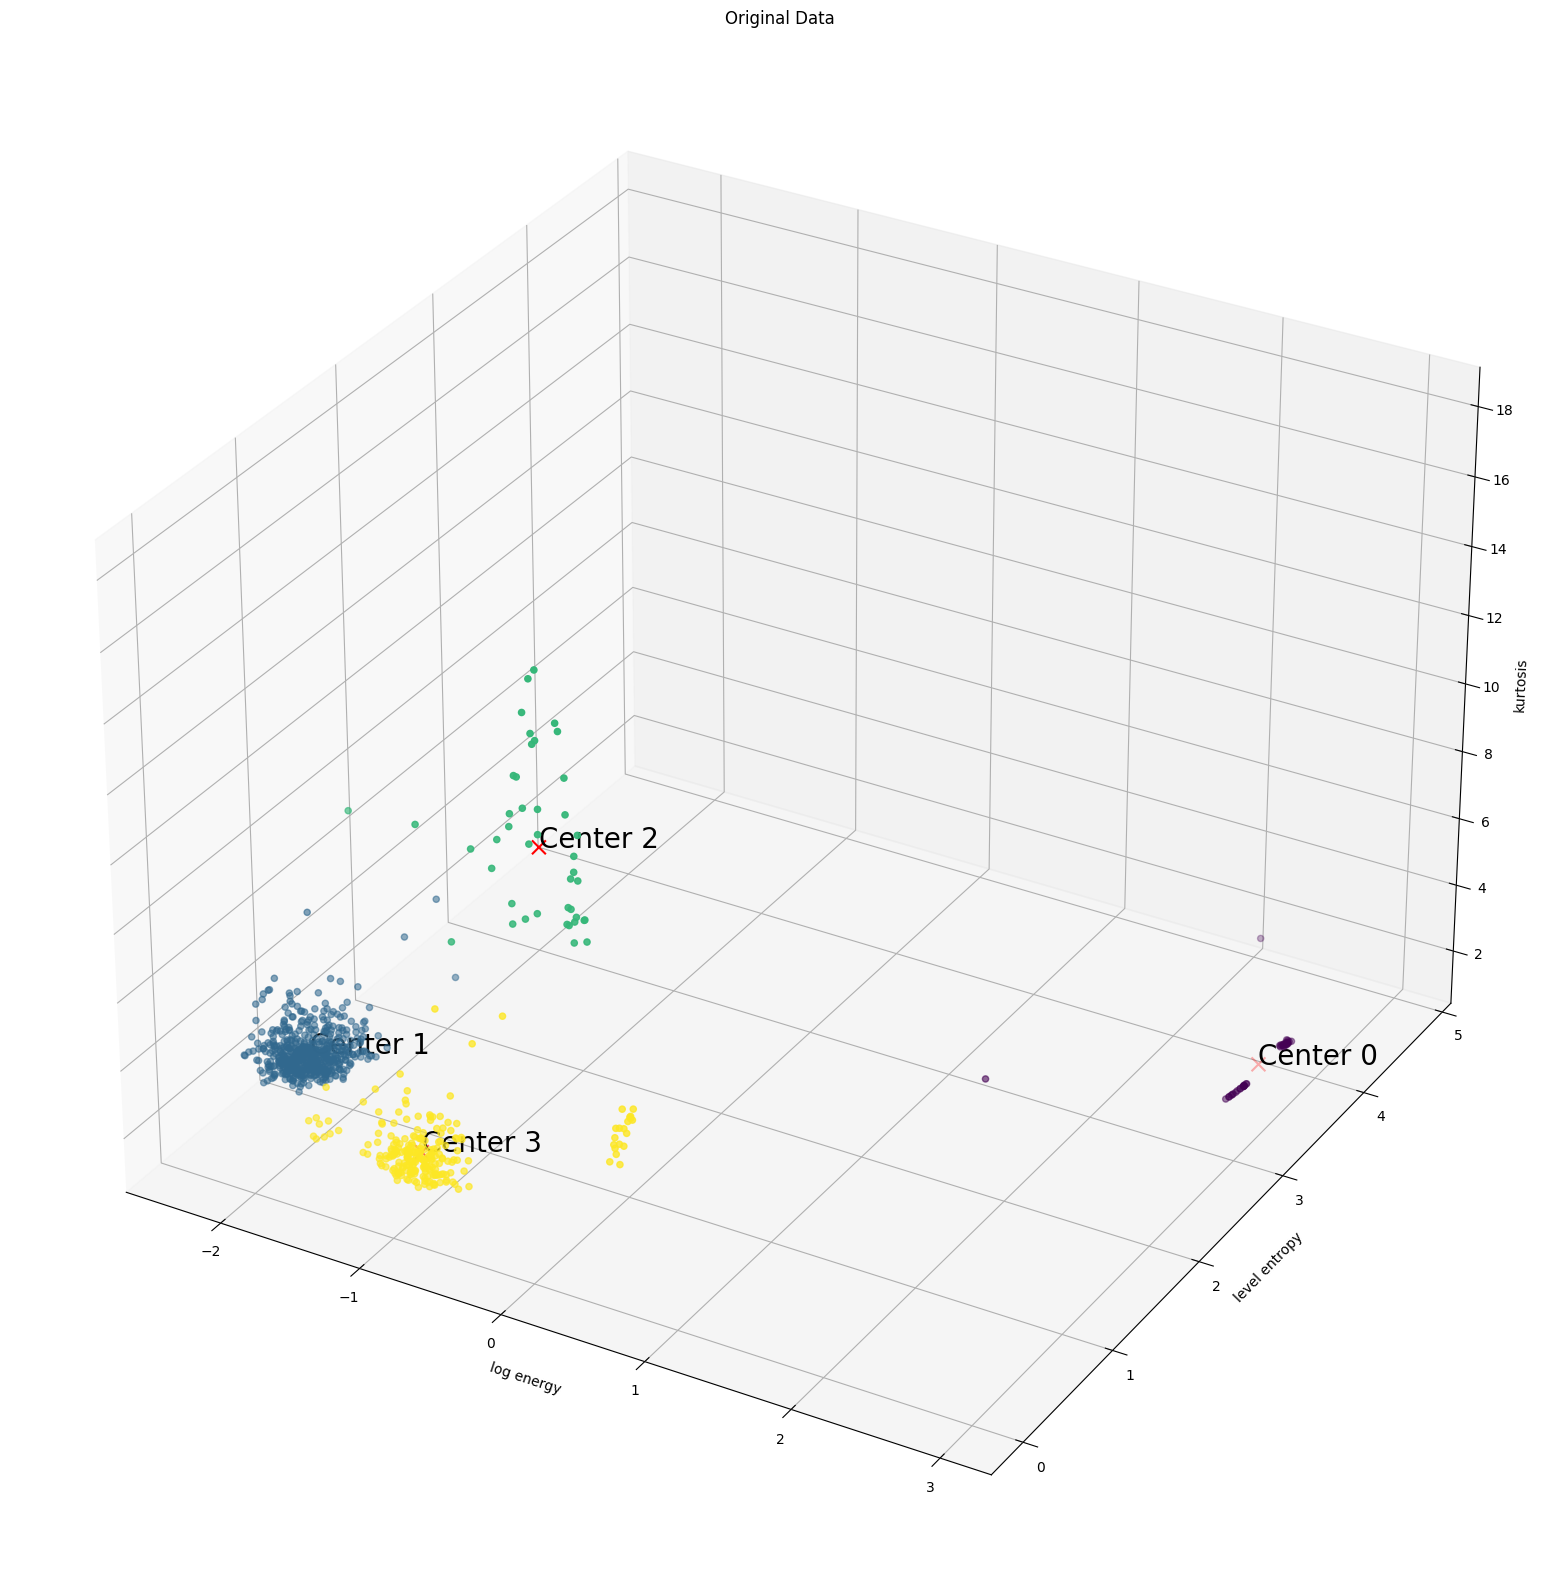

In [73]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()

### Classifying new data points

dynamics is inconsistent
clustering works better with fewer levels
need better standardisation of data

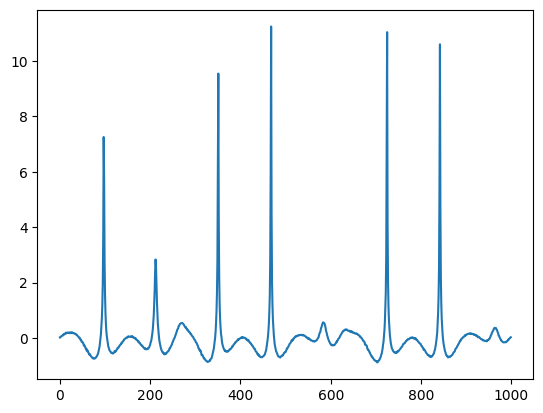

In [75]:
frequency = 2E5
pac = -1E5

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.generate_data(R_init, Rdot_init, frequency, pac, t_plot, tstep, r_measure)
data = (data - np.mean(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))
data = data[::step]

new_wpt_df, new_tr_ob = train.generate_training_data(
    data, 
    levels,
    wavelet, 
    mode,
    min_energy=min_energy,
    include_tr_ob=True
)

new_wpt_df.head()

plt.plot(data)
plt.show()

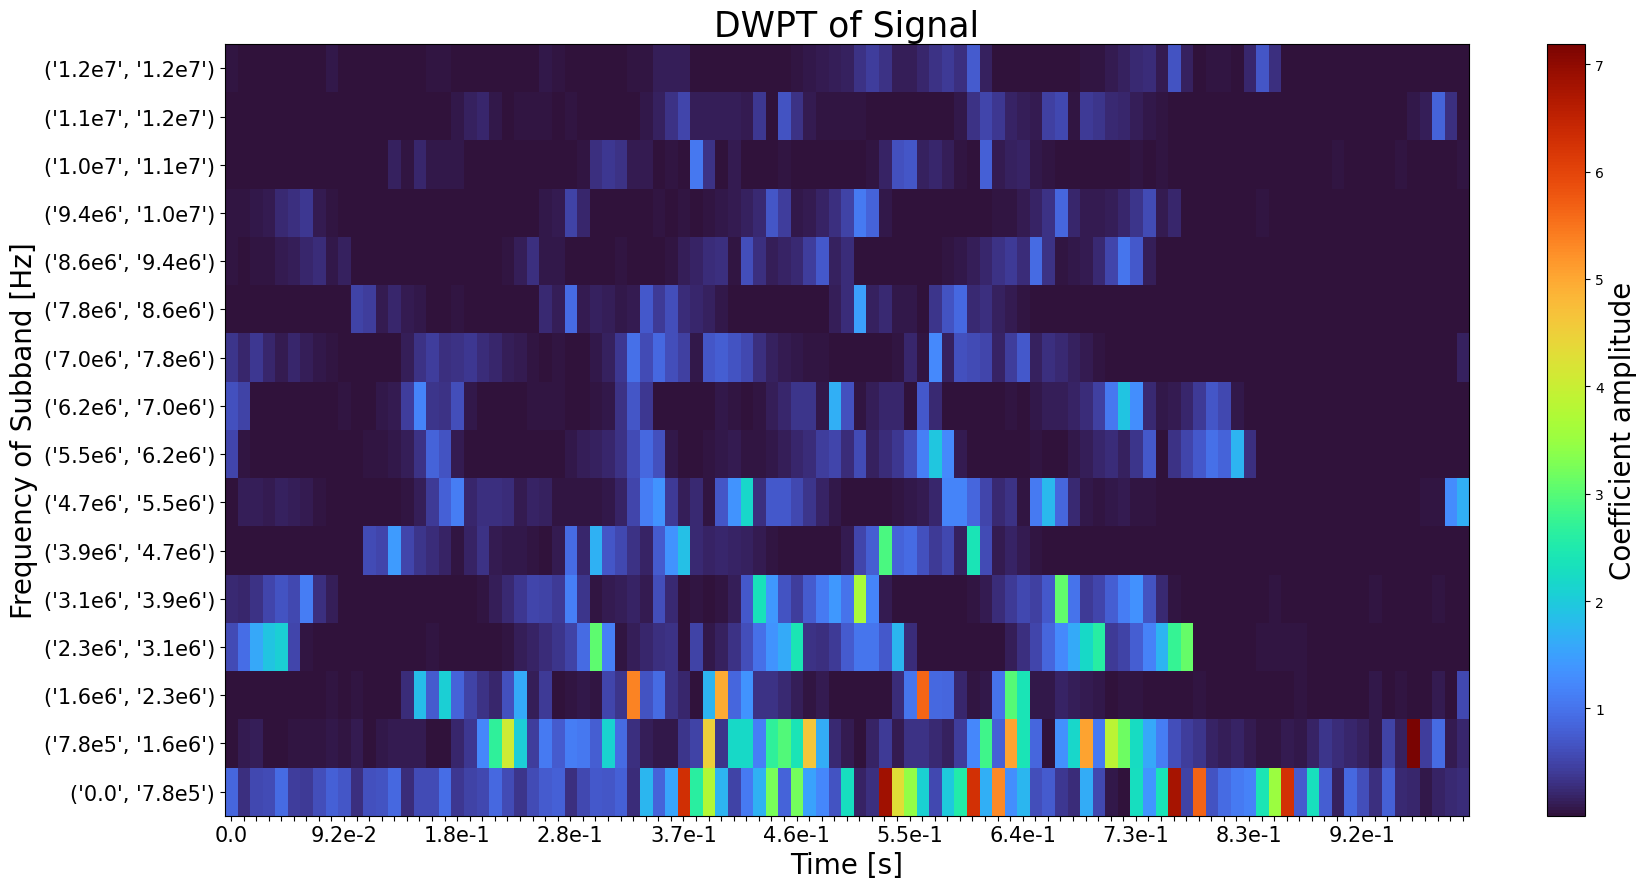

In [76]:
new_tr_ob.calc_frequencies(real_sampling_rate)
plot.heisenberg(new_tr_ob)

In [77]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# Predict membership using the cluster centers and membership matrix
new_u, *_ = fuzz.cluster.cmeans_predict(
    new_entry_normalized.T,
    cntr,
    m=m,
    error=error,
    maxiter=100,
)

new_membership_matrix = new_u.T
# Convert membership to hard cluster assignment
new_labels = np.argmax(new_u, axis=0)

# Display the predicted results
print("Predicted hard cluster assignment:", new_labels)

membership_results = pd.DataFrame()
for i, membership in enumerate(new_membership_matrix):
    membership_results.loc[i, "hard assignment"] = new_labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results

Predicted hard cluster assignment: [0 2 2 3 2 2 3 2 2 3 2 2 2 2 2 2]


,hard assignment,membership 0,membership 1,membership 2,membership 3
0,0.0,0.401225,0.181004,0.193025,0.224746
1,2.0,0.230998,0.199725,0.294453,0.274824
2,2.0,0.074481,0.093296,0.723572,0.108650
3,3.0,0.129271,0.220744,0.255334,0.394651
4,2.0,0.040438,0.063883,0.812772,0.082908
5,2.0,0.030918,0.052294,0.848718,0.068070
6,3.0,0.088628,0.205108,0.325630,0.380634
7,2.0,0.052298,0.112767,0.665975,0.168960
8,2.0,0.026486,0.052226,0.850448,0.070840
9,3.0,0.067961,0.217701,0.241444,0.472894


### Reconstructing by cluster

Reconstructed nodes by group:


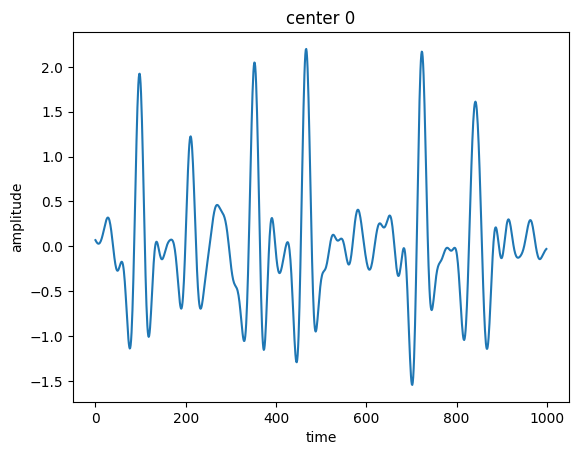

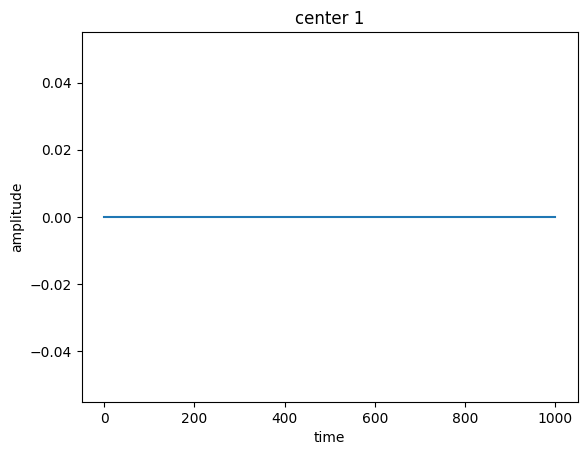

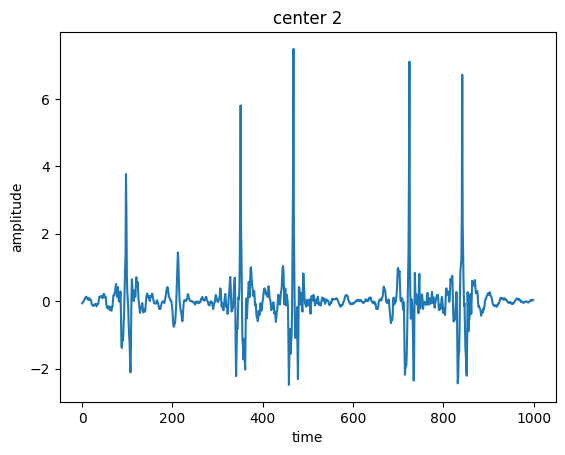

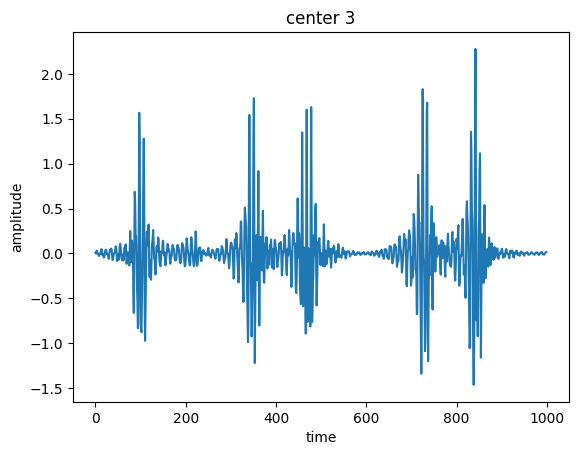

In [78]:
# Sum all reconstructions belonging to the same group
plot.plot_reconstructions_by_group(new_tr_ob, new_labels, no_clusters, order="freq")

### Plot nodes

Plot each node in the test data set alongside its membership values. Filter by the centre the node is assigned to.

In [79]:
import wavelet_transform.wpt.inverse_transform as inv
run = True
if run is True:
    plot_centres = [4]
    for i, (node, assignment) in enumerate(zip(new_tr_ob.get_level(), new_labels)):
        if assignment in plot_centres:
            print(node.energy)
            rec = inv.inv_dwpt(new_tr_ob, levels, nodes=node)
            plt.plot(rec)
            plt.title(f"memberships {new_membership_matrix[i]}")
            plt.show()
